# AV3 – Pipeline de Dados Air Quality: evidências de execução
**Disciplina:** Big Data (CEUB), Prof. Klayton R. Castro

Este notebook é executado **dentro da rede Docker `mybridge`** e consulta cada componente da arquitetura ao vivo:
MinIO, Kafka, Delta Lake (Bronze/Silver/Gold), Cassandra, Redis, API FastAPI e o histórico de execuções do Airflow.
Todas as saídas abaixo vêm da execução real.

In [1]:
import json, time, warnings
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
import requests
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
import settings, infra_check, cassandra_admin, reporting
print("Executado em", datetime.now(timezone.utc).isoformat(timespec="seconds"))

Executado em 2026-11-25T14:38:12+00:00


## 1. Ambiente: comunicação entre os contêineres na rede `mybridge`

In [2]:
apps = infra_check.run()

Host atual: 8fb567421753 (172.18.0.12)
serviço                          host:porta                 IP mybridge      latência  status
MinIO API S3                     minio:9000                 172.18.0.4          0.5ms  OK
Kafka broker                     kafka1:9092                172.18.0.6          0.4ms  OK
Spark Master (RPC)               spark-master:7077          172.18.0.7          0.4ms  OK
Spark Master (UI)                spark-master:8080          172.18.0.7          1.9ms  OK
Spark Worker (UI)                spark-worker:8081          172.18.0.9          0.5ms  OK
Cassandra (CQL)                  cassandra:9042             172.18.0.2          1.1ms  OK
Redis                            redis:6379                 172.18.0.3          0.5ms  OK
API FastAPI                      api:8000                   172.18.0.10         0.5ms  OK
Postgres (metadados Airflow)     postgres:5432              172.18.0.5          0.6ms  OK
Dashboard Streamlit              dashboard:8501          

Checagens de aplicação: {"minio_health": 200, "kafka_brokers": ["kafka1:9092"], "spark_status": "ALIVE", "spark_alive_workers": 1, "spark_cores": 3, "cassandra_version": "4.1.7", "redis_ping": true, "api_health": "ok"}
Todos os serviços estão acessíveis pela rede mybridge.


## 2. Origem e ingestão: CSV no MinIO e tópicos Kafka

In [3]:
s3 = settings.s3_client()
head = s3.head_object(Bucket=settings.BUCKET, Key=settings.SOURCE_KEY)
print(f"s3://{settings.BUCKET}/{settings.SOURCE_KEY}: {head['ContentLength']:,} bytes, ETag {head['ETag']}")
raw = s3.get_object(Bucket=settings.BUCKET, Key=settings.SOURCE_KEY)["Body"].read().decode()
print("\nPrimeiras linhas do CSV original (UCI):")
print("\n".join(raw.splitlines()[:3]))

s3://air-quality/raw/airquality.csv: 785,065 bytes, ETag "a05a884eb5a0578e20c504cc48ba7c0d"

Primeiras linhas do CSV original (UCI):
Date;Time;CO(GT);PT08.S1(CO);NMHC(GT);C6H6(GT);PT08.S2(NMHC);NOx(GT);PT08.S3(NOx);NO2(GT);PT08.S4(NO2);PT08.S5(O3);T;RH;AH;;
10/03/2004;18.00.00;2,6;1360;150;11,9;1046;166;1056;113;1692;1268;13,6;48,9;0,7578;;
10/03/2004;19.00.00;2;1292;112;9,4;955;103;1174;92;1559;972;13,3;47,7;0,7255;;


In [4]:
from confluent_kafka import Consumer, TopicPartition
from confluent_kafka.admin import AdminClient
admin = AdminClient({"bootstrap.servers": settings.KAFKA_BOOTSTRAP})
c = Consumer({"bootstrap.servers": settings.KAFKA_BOOTSTRAP, "group.id": "av3-notebook", "enable.auto.commit": False})
rows = []
for topic, meta in admin.list_topics(timeout=10).topics.items():
    if topic.startswith("__"):
        continue
    for p in sorted(meta.partitions):
        lo, hi = c.get_watermark_offsets(TopicPartition(topic, p), timeout=10)
        rows.append({"tópico": topic, "partição": p, "offset_inicial": lo, "offset_final": hi, "mensagens": hi - lo})
pd.DataFrame(rows)

,tópico,partição,offset_inicial,offset_final,mensagens
0,sensor_alerts,0,0,554,554
1,sensor_raw,0,0,18520,18520
2,sensor_raw,1,0,19446,19446
3,sensor_raw,2,0,18553,18553


In [5]:
def peek(topic, n=2, partition=0, from_end=True):
    lo, hi = c.get_watermark_offsets(TopicPartition(topic, partition), timeout=10)
    start = max(lo, hi - n) if from_end else lo
    c.assign([TopicPartition(topic, partition, start)])
    out = []
    while len(out) < min(n, hi - start):
        m = c.poll(5)
        if m is None: break
        out.append(json.loads(m.value()))
    return out
print("Mensagem em sensor_raw (JSON publicado pelo Producer):")
print(json.dumps(peek("sensor_raw", 1, from_end=False)[0], indent=2, ensure_ascii=False))
print("\nÚltimos alertas em sensor_alerts:")
for a in peek("sensor_alerts", 3): print(a)

Mensagem em sensor_raw (JSON publicado pelo Producer):
{
  "run_id": "manual__2026-11-25T12:04:41+00:00",
  "source": "s3://air-quality/raw/airquality.csv",
  "source_line": 2,
  "ingested_at": "2026-11-25T12:04:47.180842+00:00",
  "payload": {
    "date": "10/03/2004",
    "time": "18.00.00",
    "co_gt": "2,6",
    "pt08_s1_co": "1360",
    "nmhc_gt": "150",
    "c6h6_gt": "11,9",
    "pt08_s2_nmhc": "1046",
    "nox_gt": "166",
    "pt08_s3_nox": "1056",
    "no2_gt": "113",
    "pt08_s4_no2": "1692",
    "pt08_s5_o3": "1268",
    "t": "13,6",
    "rh": "48,9",
    "ah": "0,7578"
  }
}

Últimos alertas em sensor_alerts:
{'sensor_id': 'airquality-uci-01', 'event_ts': '2004-11-26T21:00:00', 'rule': 'NO2_1H', 'severity': 'alta', 'value': 205.0, 'threshold': 200.0, 'source': 'stream'}
{'sensor_id': 'airquality-uci-01', 'event_ts': '2004-11-26T18:00:00', 'rule': 'CO_1H', 'severity': 'alta', 'value': 10.1, 'threshold': 10.0, 'source': 'stream'}
{'sensor_id': 'airquality-uci-01', 'event_ts

## 3. Lakehouse Delta Lake no MinIO (lido com `deltalake`, sem Spark)

In [6]:
from deltalake import DeltaTable
def dt(path): return DeltaTable(settings.to_s3_uri(path), storage_options=settings.delta_storage_options())
tables = {"bronze/sensor_raw": settings.BRONZE_PATH, "silver/airquality": settings.SILVER_PATH,
          "gold/daily_summary": settings.GOLD_DAILY_PATH, "gold/hourly_profile": settings.GOLD_HOURLY_PATH,
          "gold/alerts": settings.GOLD_ALERTS_PATH}
summary = []
for name, path in tables.items():
    t = dt(path)
    summary.append({"tabela": name, "versão": t.version(), "arquivos": len(t.files()),
                    "linhas": t.to_pyarrow_dataset().count_rows(),
                    "partições": ", ".join(t.metadata().partition_columns) or "-"})
pd.DataFrame(summary)

,tabela,versão,arquivos,linhas,partições
0,bronze/sensor_raw,3,6,37428,ingest_date
1,silver/airquality,6,14,9357,"year, month"
2,gold/daily_summary,1,5,391,year
3,gold/hourly_profile,1,3,72,-
4,gold/alerts,1,14,537,alert_month


In [7]:
bronze = dt(settings.BRONZE_PATH).to_pandas(columns=["bronze_run_id", "kafka_partition", "kafka_offset", "raw_value"])
print("Bronze guarda o JSON bruto exatamente como chegou do Kafka:")
print(bronze.iloc[0]["raw_value"][:300], "...")
bronze.groupby("bronze_run_id").size().rename("mensagens por carga").to_frame()

Bronze guarda o JSON bruto exatamente como chegou do Kafka:
{"run_id": "manual__av3_rerun_20261125T135717", "source": "s3://air-quality/raw/airquality.csv", "source_line": 2, "ingested_at": "2026-11-25T13:57:36.015440+00:00", "payload": {"date": "10/03/2004", "time": "18.00.00", "co_gt": "2,6", "pt08_s1_co": "1360", "nmhc_gt": "150", "c6h6_gt": "11,9", "pt08 ...


,mensagens por carga
bronze_run_id,
manual__av3_full_20261125T131759,9357
manual__av3_rerun_20261125T135717,9357
scheduled__2026-11-24T00:00:00+00:00,18714


In [8]:
silver_dt = dt(settings.SILVER_PATH)
silver = silver_dt.to_pandas()
print(silver.dtypes.to_string())
silver.sort_values("event_ts").head(5)[["event_ts", "co_mg_m3", "no2_ug_m3", "benzene_ug_m3", "temperature_c",
                                        "relative_humidity_pct", "missing_measures", "run_id"]]

event_ts                 datetime64[us, UTC]
event_date                            object
year                                   int32
month                                  int32
day                                    int32
hour                                   int32
day_of_week                           object
is_weekend                              bool
co_mg_m3                             float64
nmhc_ug_m3                           float64
benzene_ug_m3                        float64
nox_ppb                              float64
no2_ug_m3                            float64
sensor_co_resp                       float64
sensor_nmhc_resp                     float64
sensor_nox_resp                      float64
sensor_no2_resp                      float64
sensor_o3_resp                       float64
temperature_c                        float64
relative_humidity_pct                float64
absolute_humidity                    float64
missing_measures                       int32
run_id    

,event_ts,co_mg_m3,no2_ug_m3,benzene_ug_m3,temperature_c,relative_humidity_pct,missing_measures,run_id
0,2004-03-10 18:00:00+00:00,2.6,113.0,11.9,13.6,48.9,0,manual__av3_full_20261125T131759
1,2004-03-10 19:00:00+00:00,2.0,92.0,9.4,13.3,47.7,0,manual__av3_full_20261125T131759
2,2004-03-10 20:00:00+00:00,2.2,114.0,9.0,11.9,54.0,0,manual__av3_full_20261125T131759
3,2004-03-10 21:00:00+00:00,2.2,122.0,9.2,11.0,60.0,0,manual__av3_full_20261125T131759
4,2004-03-10 22:00:00+00:00,1.6,116.0,6.5,11.2,59.6,0,manual__av3_full_20261125T131759


**Histórico e time travel do Delta.** Cada carga gera uma versão. As versões anteriores continuam consultáveis.

In [9]:
hist = pd.DataFrame(silver_dt.history())[["version", "timestamp", "operation", "operationMetrics"]]
hist["timestamp"] = pd.to_datetime(hist["timestamp"], unit="ms")
hist["métricas"] = hist["operationMetrics"].apply(lambda m: {k: m[k] for k in m if k in (
    "numOutputRows", "numTargetRowsInserted", "numTargetRowsUpdated", "numSourceRows")} if m else {})
display(hist.drop(columns="operationMetrics"))
v0 = DeltaTable(settings.to_s3_uri(settings.SILVER_PATH), version=0, storage_options=settings.delta_storage_options())
print(f"Silver na versão 0: {v0.to_pyarrow_dataset().count_rows()} linhas | versão atual ({silver_dt.version()}): {len(silver)} linhas")
print("CHECK constraints:", {k.split('.')[-1]: v for k, v in silver_dt.metadata().configuration.items() if 'constraints' in k})

,version,timestamp,operation,métricas
0,6,2026-11-25 14:26:41.344,MERGE,"{'numOutputRows': '9357', 'numSourceRows': '93..."
1,5,2026-11-25 14:26:17.058,ADD CONSTRAINT,{}
2,4,2026-11-25 14:26:12.611,ADD CONSTRAINT,{}
3,3,2026-11-25 14:26:07.124,ADD CONSTRAINT,{}
4,2,2026-11-25 13:45:26.024,MERGE,"{'numOutputRows': '9357', 'numSourceRows': '93..."
5,1,2026-11-25 13:36:49.161,ADD CONSTRAINT,{}
6,0,2026-11-25 13:36:18.188,WRITE,{'numOutputRows': '9357'}


Silver na versão 0: 9357 linhas | versão atual (6): 9357 linhas
CHECK constraints: {'rh_range': 'relative_humidity_pct IS NULL OR relative_humidity_pct BETWEEN 0 AND 100', 'event_ts_not_null': 'event_ts IS NOT NULL', 'co_non_negative': 'co_mg_m3 IS NULL OR co_mg_m3 >= 0', 'no2_non_negative': 'no2_ug_m3 IS NULL OR no2_ug_m3 >= 0'}


## 4. Qualidade dos dados: relatórios gerados pelo pipeline

In [10]:
runs = cassandra_admin.connect(retries=3, wait=2)[1].execute(
    "SELECT run_id, status FROM airquality.pipeline_runs WHERE pipeline='pipeline_airquality' LIMIT 1").one()
RUN = runs.run_id
print("Última execução registrada:", RUN, runs.status)
silver_rep = reporting.get_report(RUN, "silver")
q = pd.DataFrame({"-200 → nulo": silver_rep["sentinel_minus_200_to_null"],
                  "fora da faixa → nulo": pd.Series(silver_rep["out_of_range_to_null"])}).fillna(0).astype(int)
print({k: silver_rep[k] for k in ("input_messages", "malformed_messages", "invalid_timestamp",
                                  "duplicates_in_batch", "rows_inserted", "rows_updated", "rows_unchanged", "rows_total")})
q

Última execução registrada: manual__av3_rerun_20261125T135717 SUCCESS
{'input_messages': 9357, 'malformed_messages': 0, 'invalid_timestamp': 0, 'duplicates_in_batch': 0, 'rows_inserted': 0, 'rows_updated': 0, 'rows_unchanged': 9357, 'rows_total': 9357}


,-200 → nulo,fora da faixa → nulo
absolute_humidity,366,0
benzene_ug_m3,366,0
co_mg_m3,1683,0
nmhc_ug_m3,8443,0
no2_ug_m3,1642,0
nox_ppb,1639,0
relative_humidity_pct,366,0
sensor_co_resp,366,0
sensor_nmhc_resp,366,0
sensor_no2_resp,366,0


In [11]:
val = reporting.get_report(RUN, "validation")
print(f"Validação: {val['status']} ({val['checks_passed']}/{val['checks_total']})")
pd.DataFrame(val["checks"])[["layer", "check", "ok", "detail"]]

Validação: PASSED (20/20)


,layer,check,ok,detail
0,bronze,mensagens do producer = fatia gravada na Bronze,True,producer=9357 lidas=9357 na tabela=9357
1,bronze,nenhuma mensagem Kafka duplicada na Bronze,True,"37428 linhas, 37428 chaves únicas (histórico d..."
2,silver,Silver não vazia,True,"9357 linhas, versão Delta 6"
3,silver,balanço do lote,True,9357 + 0 + 0 + 0 = 9357
4,silver,event_ts único e sem nulos,True,únicos=9357 nulos=0
5,silver,event_ts é timestamp,True,"timestamp[us, tz=UTC]"
6,silver,medidas são double,True,8 colunas float64
7,silver,sem sentinela -200,True,ocorrências=0
8,silver,intervalo temporal,True,2004-03-10 18:00:00+00:00 -> 2005-04-04 14:00:...
9,silver,CHECK constraints ativas no Delta,True,"['delta.constraints.co_non_negative', 'delta.c..."


## 5. Camada de serviço: Apache Cassandra (modelagem orientada a consultas)

In [12]:
cluster, cs = cassandra_admin.connect(retries=3, wait=2)
ks = settings.CASSANDRA_KEYSPACE
counts = {t: cs.execute(f"SELECT COUNT(*) FROM {ks}.{t}", timeout=120).one()[0]
          for t in ["readings_by_day", "daily_summary", "hourly_profile", "alerts_by_month", "latest_readings", "pipeline_runs"]}
pd.Series(counts, name="linhas").to_frame()

,linhas
readings_by_day,9357
daily_summary,391
hourly_profile,72
alerts_by_month,537
latest_readings,273
pipeline_runs,2


In [13]:
print("Q1: leituras de um dia (1 partição)")
display(pd.DataFrame(list(cs.execute(f"SELECT event_ts, co_mg_m3, no2_ug_m3, temperature_c, source FROM {ks}.readings_by_day WHERE day='2004-11-17' LIMIT 6"))))
print("Q4: alertas de um mês, mais recentes primeiro")
display(pd.DataFrame(list(cs.execute(f"SELECT * FROM {ks}.alerts_by_month WHERE month='2005-02' LIMIT 6"))))
print("Q6: histórico de execuções da DAG")
display(pd.DataFrame(list(cs.execute(f"SELECT started_at, run_id, status, duration_s, rows_silver, rows_inserted, rows_updated, alerts, checks_passed, checks_total FROM {ks}.pipeline_runs WHERE pipeline='pipeline_airquality' LIMIT 5"))))

Q1: leituras de um dia (1 partição)


,event_ts,co_mg_m3,no2_ug_m3,temperature_c,source
0,2004-11-17 00:00:00,1.7,107.0,9.5,batch
1,2004-11-17 01:00:00,1.6,121.0,7.7,batch
2,2004-11-17 02:00:00,1.1,85.0,8.4,batch
3,2004-11-17 03:00:00,0.8,NaN,7.9,batch
4,2004-11-17 04:00:00,0.7,68.0,6.2,batch
5,2004-11-17 05:00:00,0.8,69.0,6.8,batch


Q4: alertas de um mês, mais recentes primeiro


,month,event_ts,rule,severity,source,threshold,value
0,2005-02,2005-02-25 00:00:00,NO2_1H,alta,batch,200.0,202.0
1,2005-02,2005-02-24 22:00:00,NO2_1H,alta,batch,200.0,227.0
2,2005-02,2005-02-24 21:00:00,NO2_1H,alta,batch,200.0,262.0
3,2005-02,2005-02-24 20:00:00,NO2_1H,alta,batch,200.0,265.0
4,2005-02,2005-02-24 19:00:00,NO2_1H,alta,batch,200.0,260.0
5,2005-02,2005-02-24 18:00:00,NO2_1H,alta,batch,200.0,270.0


Q6: histórico de execuções da DAG


,started_at,run_id,status,duration_s,rows_silver,rows_inserted,rows_updated,alerts,checks_passed,checks_total
0,2026-11-25 13:57:26.669,manual__av3_rerun_20261125T135717,SUCCESS,2088.878762,9357,0,0,537,20,20
1,2026-11-25 13:27:57.641,manual__av3_full_20261125T131759,FAILED,1350.977071,9357,0,0,537,19,20


## 6. API FastAPI com cache Redis

In [14]:
API = settings.API_URL
import redis; r = redis.Redis(host=settings.REDIS_HOST)
for k in r.scan_iter("api:summary:*"): r.delete(k)   # força MISS na primeira chamada
for i in (1, 2, 3):
    t0 = time.perf_counter(); resp = requests.get(f"{API}/api/v1/summary"); ms = (time.perf_counter() - t0) * 1000
    print(f"chamada {i}: X-Cache={resp.headers['X-Cache']:4}  {ms:6.1f} ms")
print(json.dumps(resp.json(), indent=2, ensure_ascii=False))
print("cache:", requests.get(f"{API}/cache/stats").json())

chamada 1: X-Cache=MISS    71.7 ms
chamada 2: X-Cache=HIT      4.3 ms
chamada 3: X-Cache=HIT      3.1 ms
{
  "start": "2004-03-10",
  "end": "2005-04-04",
  "days": 391,
  "readings": 9357,
  "temperature_avg_c": 18.29,
  "co_avg_mg_m3": 2.14,
  "no2_avg_ug_m3": 111.9,
  "co_max_mg_m3": 11.9,
  "no2_max_ug_m3": 340.0,
  "alerts": 537,
  "completeness_avg_pct": 86.27
}
cache: {'hits': 9, 'misses': 11, 'hit_ratio': 0.45, 'keys': 8, 'ttl_seconds': 600}


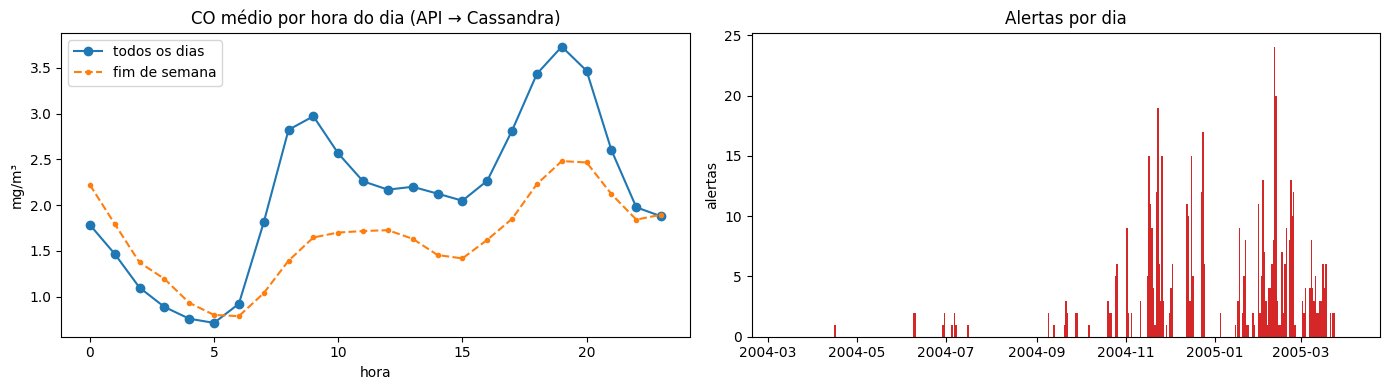

In [15]:
prof = pd.DataFrame(requests.get(f"{API}/api/v1/profile/hourly", params={"profile": "all"}).json()).sort_values("hour")
wk = pd.DataFrame(requests.get(f"{API}/api/v1/profile/hourly", params={"profile": "weekend"}).json()).sort_values("hour")
daily = pd.DataFrame(requests.get(f"{API}/api/v1/daily").json()); daily["day"] = pd.to_datetime(daily["day"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(prof["hour"], prof["co_avg"], marker="o", label="todos os dias")
ax[0].plot(wk["hour"], wk["co_avg"], marker=".", ls="--", label="fim de semana")
ax[0].set(title="CO médio por hora do dia (API → Cassandra)", xlabel="hora", ylabel="mg/m³"); ax[0].legend()
ax[1].bar(daily["day"], daily["alerts"], width=1.0, color="tab:red")
ax[1].set(title="Alertas por dia", ylabel="alertas")
plt.tight_layout(); plt.show()

## 7. Processamento contínuo (Spark Structured Streaming)

In [16]:
st = requests.get(f"{API}/api/v1/stream/status").json()
print(json.dumps(st, indent=2))
latest = pd.DataFrame(requests.get(f"{API}/api/v1/latest", params={"limit": 8}).json())
latest[["received_at", "event_ts", "co_mg_m3", "no2_ug_m3", "temperature_c", "alert_rules"]] if not latest.empty else "sem leituras de streaming"


{
  "last_batch": {
    "batch_id": 11,
    "rows": 20,
    "alerts": 0,
    "last_event_ts": "2004-12-04 20:00:00",
    "processed_at": "2026-11-25T14:36:06.288151+00:00"
  },
  "rows_total": 273,
  "alerts_total": 17
}


,received_at,event_ts,co_mg_m3,no2_ug_m3,temperature_c,alert_rules
0,2026-11-25T14:35:59.627000+00:00,2004-12-04T20:00:00+00:00,2.5,115.0,13.4,
1,2026-11-25T14:35:59.126000+00:00,2004-12-04T19:00:00+00:00,1.9,108.0,13.1,
2,2026-11-25T14:35:58.626000+00:00,2004-12-04T18:00:00+00:00,3.1,120.0,13.1,
3,2026-11-25T14:35:58.125000+00:00,2004-12-04T17:00:00+00:00,2.3,120.0,12.7,
4,2026-11-25T14:35:57.625000+00:00,2004-12-04T16:00:00+00:00,2.5,107.0,12.3,
5,2026-11-25T14:35:57.125000+00:00,2004-12-04T15:00:00+00:00,2.6,115.0,11.9,
6,2026-11-25T14:35:56.624000+00:00,2004-12-04T14:00:00+00:00,2.5,103.0,11.9,
7,2026-11-25T14:35:56.123000+00:00,2004-12-04T13:00:00+00:00,3.1,124.0,11.8,


In [17]:
cluster.shutdown(); c.close(); print('Fim das evidências.')

Fim das evidências.
